In [2]:
import sys
from pathlib import Path

AI_ROOT = Path(
    "/content/drive/MyDrive/TRON/AI"
)

if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

In [3]:
from src.preprocess import (
    SAMPLE_RATE,
    INPUT_SAMPLES,
    NUM_FRAMES,
    NUM_FFT_BINS,
    NUM_MEL_BINS,
    pcm16_to_float32,
    stft_power,
    mel_power,
    log_mel,
    preprocess_pcm16,
    to_model_input,
    MEL_FILTERBANK,
)

print("Sample rate :", SAMPLE_RATE)
print("Input       :", INPUT_SAMPLES)
print("Frames      :", NUM_FRAMES)
print("FFT bins    :", NUM_FFT_BINS)
print("Mel bins    :", NUM_MEL_BINS)
print("Mel FB      :", MEL_FILTERBANK.shape)

Sample rate : 16000
Input       : 16000
Frames      : 98
FFT bins    : 257
Mel bins    : 40
Mel FB      : (257, 40)


In [4]:
import numpy as np

pcm_zero = np.zeros(
    16000,
    dtype=np.int16,
)

feature_zero = preprocess_pcm16(
    pcm_zero
)

print(
    "shape:",
    feature_zero.shape
)

print(
    "dtype:",
    feature_zero.dtype
)

print(
    "min:",
    feature_zero.min()
)

print(
    "max:",
    feature_zero.max()
)

print(
    "unique:",
    np.unique(feature_zero)
)

shape: (98, 40)
dtype: float32
min: -100.0
max: -100.0
unique: [-100.]


In [5]:
t = np.arange(
    16000,
    dtype=np.float32,
) / 16000.0

x = (
    0.5
    * np.sin(
        2.0
        * np.pi
        * 440.0
        * t
    )
)

pcm_440 = np.round(
    x * 32767.0
).astype(np.int16)

feature_440 = preprocess_pcm16(
    pcm_440
)

print(
    feature_440.shape
)

print(
    "finite:",
    np.isfinite(
        feature_440
    ).all()
)

print(
    "min:",
    feature_440.min()
)

print(
    "max:",
    feature_440.max()
)

(98, 40)
finite: True
min: -78.29255
max: 35.067387


In [6]:
mean_mel = feature_440.mean(
    axis=0
)

peak_mel_bin = np.argmax(
    mean_mel
)

print(
    "Peak Mel bin:",
    peak_mel_bin
)

print(
    "Peak value:",
    mean_mel[
        peak_mel_bin
    ]
)

Peak Mel bin: 6
Peak value: 35.06736


In [7]:
pcm_impulse = np.zeros(
    16000,
    dtype=np.int16,
)

pcm_impulse[8000] = 32767

feature_impulse = preprocess_pcm16(
    pcm_impulse
)

print(
    feature_impulse.shape
)

print(
    "finite:",
    np.isfinite(
        feature_impulse
    ).all()
)

print(
    "min:",
    feature_impulse.min()
)

print(
    "max:",
    feature_impulse.max()
)

(98, 40)
finite: True
min: -100.0
max: 11.0614605


In [8]:
x = pcm16_to_float32(
    pcm_440
)

power = stft_power(x)

mel = mel_power(power)

feature = log_mel(mel)

model_input = to_model_input(
    feature
)

assert x.shape == (16000,)
assert x.dtype == np.float32

assert power.shape == (98, 257)
assert power.dtype == np.float32

assert mel.shape == (98, 40)
assert mel.dtype == np.float32

assert feature.shape == (98, 40)
assert feature.dtype == np.float32

assert model_input.shape == (
    1,
    98,
    40,
    1,
)

assert model_input.dtype == np.float32

assert np.isfinite(
    feature
).all()

print(
    "AI-04 basic preprocessing check: OK"
)

AI-04 basic preprocessing check: OK


In [12]:
from pathlib import Path
from scipy.io import wavfile
import pandas as pd
import numpy as np

DATASET_ROOT = Path(
    "/content/drive/MyDrive/TRON/AI/dataset"
)

OUTPUT_ROOT = (
    DATASET_ROOT
    / "processed"
    / "clips_16k_1s"
)

CLIP_MANIFEST = (
    DATASET_ROOT
    / "metadata"
    / "ai03"
    / "clip_manifest.csv"
)

manifest = pd.read_csv(CLIP_MANIFEST)

for class_name in ["OTHER", "SNORE", "COUGH"]:

    row = manifest[
        manifest["class_name"] == class_name
    ].iloc[0]

    path = OUTPUT_ROOT / row["relative_path"]

    sr, pcm = wavfile.read(path)

    assert sr == 16000
    assert pcm.dtype == np.int16
    assert pcm.shape == (16000,)

    feature = preprocess_pcm16(pcm)

    assert feature.shape == (98, 40)
    assert np.isfinite(feature).all()

    print(
        class_name,
        path.name,
        feature.min(),
        feature.max(),
    )

print("Real audio preprocessing check: OK")

OTHER esc50__1-100038-A-14.wav -49.06559 33.224205
SNORE esc50__1-20545-A-28.wav -54.189316 26.345453
COUGH esc50__1-19111-A-24.wav -100.0 30.581457
Real audio preprocessing check: OK


In [14]:
test_cases = [
    ("ESC-50", "OTHER"),
    ("ESC-50", "SNORE"),
    ("ESC-50", "COUGH"),
    ("AudioSet Strong", "SNORE"),
    ("Coswara", "COUGH"),
]

for dataset_name, class_name in test_cases:

    row = manifest[
        (manifest["source_dataset"] == dataset_name)
        & (manifest["class_name"] == class_name)
    ].iloc[0]

    path = OUTPUT_ROOT / row["relative_path"]

    sr, pcm = wavfile.read(path)

    assert sr == 16000
    assert pcm.dtype == np.int16
    assert pcm.shape == (16000,)

    feature = preprocess_pcm16(pcm)

    assert feature.shape == (98, 40)
    assert feature.dtype == np.float32
    assert np.isfinite(feature).all()

    print(
        f"{dataset_name:16s}",
        f"{class_name:5s}",
        path.name,
        f"min={feature.min():.3f}",
        f"max={feature.max():.3f}",
    )

print("Dataset-specific preprocessing check: OK")

ESC-50           OTHER esc50__1-100038-A-14.wav min=-49.066 max=33.224
ESC-50           SNORE esc50__1-20545-A-28.wav min=-54.189 max=26.345
ESC-50           COUGH esc50__1-19111-A-24.wav min=-100.000 max=30.581
AudioSet Strong  SNORE audioset__audioset_-7xDzCwyAco_30000_event_000.wav min=-70.912 max=22.649
Coswara          COUGH coswara__20200413_0Rlzhiz6bybk77wdLjxwy7yLDhg1_cough-heavy.wav min=-74.930 max=31.703
Dataset-specific preprocessing check: OK


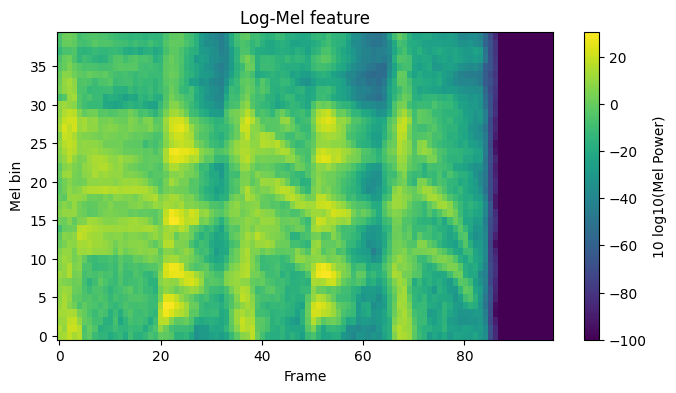

In [13]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(8, 4)
)

plt.imshow(
    feature.T,
    origin="lower",
    aspect="auto",
)

plt.xlabel("Frame")
plt.ylabel("Mel bin")
plt.title("Log-Mel feature")

plt.colorbar(
    label="10 log10(Mel Power)"
)

plt.show()

#### 既存の音声処理ライブラリとの比較

In [15]:
import librosa

print("librosa version:", librosa.__version__)

librosa version: 0.11.0


In [16]:
import numpy as np
import librosa

from src.preprocess import (
    SAMPLE_RATE,
    FFT_LENGTH,
    NUM_MEL_BINS,
    FMIN,
    FMAX,
    MEL_FILTERBANK,
)

librosa_mel = librosa.filters.mel(
    sr=SAMPLE_RATE,
    n_fft=FFT_LENGTH,
    n_mels=NUM_MEL_BINS,
    fmin=FMIN,
    fmax=FMAX,
    htk=True,
    norm=None,
    dtype=np.float32,
)

print("Our filterbank     :", MEL_FILTERBANK.shape)
print("Librosa filterbank :", librosa_mel.shape)

Our filterbank     : (257, 40)
Librosa filterbank : (40, 257)


In [17]:
librosa_mel_t = librosa_mel.T

print(
    "Transposed librosa:",
    librosa_mel_t.shape
)

assert librosa_mel_t.shape == MEL_FILTERBANK.shape

Transposed librosa: (257, 40)


In [18]:
diff = (
    MEL_FILTERBANK
    - librosa_mel_t
)

abs_diff = np.abs(diff)

print(
    "Max abs diff :",
    abs_diff.max()
)

print(
    "Mean abs diff:",
    abs_diff.mean()
)

print(
    "RMSE         :",
    np.sqrt(
        np.mean(diff ** 2)
    )
)

Max abs diff : 0.0
Mean abs diff: 0.0
RMSE         : 0.0


In [19]:
print(
    "allclose:",
    np.allclose(
        MEL_FILTERBANK,
        librosa_mel_t,
        rtol=1e-5,
        atol=1e-6,
    )
)

allclose: True


In [20]:
assert MEL_FILTERBANK.shape == (257, 40)

assert np.isfinite(
    MEL_FILTERBANK
).all()

assert (
    MEL_FILTERBANK >= 0.0
).all()

assert (
    MEL_FILTERBANK <= 1.0
).all()

# 各Mel filterに必ず正のweightが存在する
assert (
    MEL_FILTERBANK.max(axis=0) > 0.0
).all()

print(
    "Mel filterbank structural check: OK"
)

Mel filterbank structural check: OK


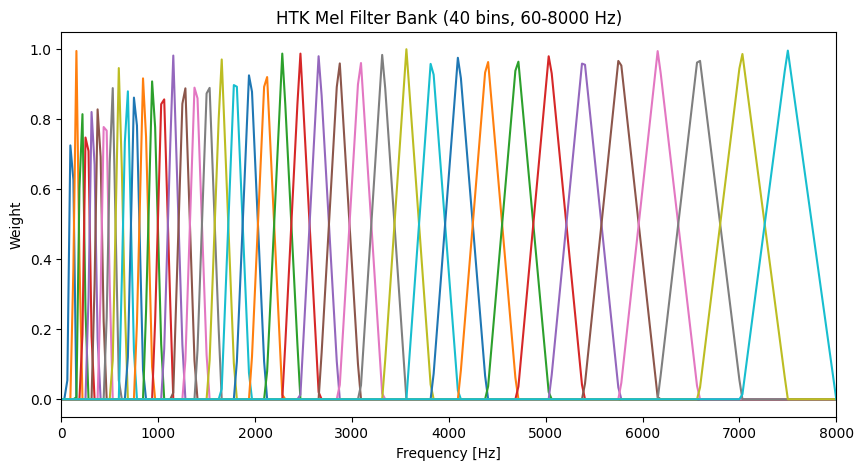

In [21]:
import matplotlib.pyplot as plt

fft_freqs = np.linspace(
    0.0,
    SAMPLE_RATE / 2,
    FFT_LENGTH // 2 + 1,
)

plt.figure(
    figsize=(10, 5)
)

for i in range(NUM_MEL_BINS):
    plt.plot(
        fft_freqs,
        MEL_FILTERBANK[:, i],
    )

plt.xlabel("Frequency [Hz]")
plt.ylabel("Weight")
plt.title(
    "HTK Mel Filter Bank "
    "(40 bins, 60-8000 Hz)"
)
plt.xlim(
    0,
    SAMPLE_RATE / 2,
)

plt.show()

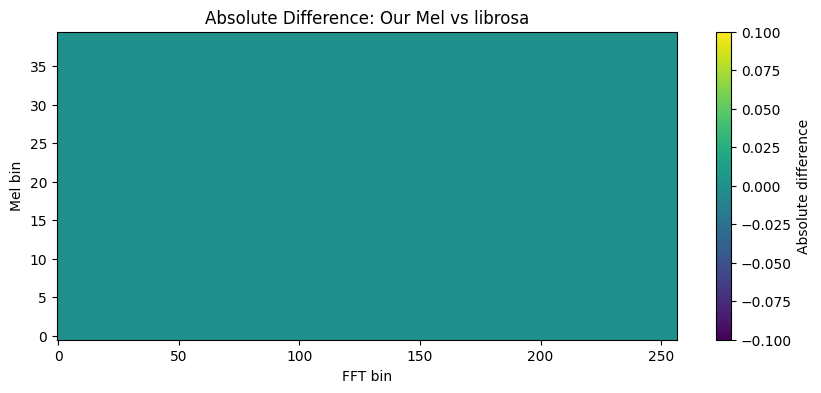

In [22]:
plt.figure(
    figsize=(10, 4)
)

plt.imshow(
    abs_diff.T,
    origin="lower",
    aspect="auto",
)

plt.xlabel("FFT bin")
plt.ylabel("Mel bin")
plt.title(
    "Absolute Difference: "
    "Our Mel vs librosa"
)

plt.colorbar(
    label="Absolute difference"
)

plt.show()

In [23]:
from src.preprocess import (
    pcm16_to_float32,
    stft_power,
)

x = pcm16_to_float32(
    pcm_440
)

power = stft_power(x)

our_mel = (
    power
    @ MEL_FILTERBANK
)

librosa_ref_mel = (
    power
    @ librosa_mel_t
)

mel_diff = np.abs(
    our_mel
    - librosa_ref_mel
)

print(
    "Mel output max abs diff :",
    mel_diff.max()
)

print(
    "Mel output mean abs diff:",
    mel_diff.mean()
)

print(
    "Mel output allclose:",
    np.allclose(
        our_mel,
        librosa_ref_mel,
        rtol=1e-5,
        atol=1e-6,
    )
)

Mel output max abs diff : 0.0
Mel output mean abs diff: 0.0
Mel output allclose: True


In [24]:
assert MEL_FILTERBANK.shape == (
    257,
    40,
)

assert np.isfinite(
    MEL_FILTERBANK
).all()

assert (
    MEL_FILTERBANK >= 0
).all()

assert np.allclose(
    MEL_FILTERBANK,
    librosa_mel_t,
    rtol=1e-5,
    atol=1e-6,
)

assert np.allclose(
    our_mel,
    librosa_ref_mel,
    rtol=1e-5,
    atol=1e-6,
)

print(
    "AI-04 Mel filterbank reference check: OK"
)

AI-04 Mel filterbank reference check: OK


#### STFTの数値検証

In [25]:
import numpy as np

from src.preprocess import (
    FRAME_LENGTH,
    FFT_LENGTH,
    NUM_FRAMES,
    periodic_hann_window,
    frame_signal,
    stft_power,
    pcm16_to_float32,
)

x = pcm16_to_float32(pcm_440)

frames = frame_signal(x)
window = periodic_hann_window()

our_power = stft_power(x)

# NumPy reference
ref_power = []

for i in range(NUM_FRAMES):

    frame = frames[i] * window

    spectrum = np.fft.rfft(
        frame,
        n=FFT_LENGTH,
    )

    power = (
        spectrum.real ** 2
        + spectrum.imag ** 2
    )

    ref_power.append(power)

ref_power = np.asarray(
    ref_power,
    dtype=np.float32,
)

print("Our STFT :", our_power.shape)
print("Ref STFT :", ref_power.shape)

diff = np.abs(
    our_power - ref_power
)

print(
    "Max abs diff :",
    diff.max()
)

print(
    "Mean abs diff:",
    diff.mean()
)

print(
    "allclose:",
    np.allclose(
        our_power,
        ref_power,
        rtol=1e-5,
        atol=1e-6,
    )
)

Our STFT : (98, 257)
Ref STFT : (98, 257)
Max abs diff : 0.0007324219
Mean abs diff: 1.4031576e-06
allclose: True


In [26]:
N = FRAME_LENGTH

n = np.arange(
    N,
    dtype=np.float64,
)

hann_reference = (
    0.5
    - 0.5
    * np.cos(
        2.0
        * np.pi
        * n
        / N
    )
).astype(np.float32)

our_hann = periodic_hann_window()

print(
    "Hann max abs diff:",
    np.max(
        np.abs(
            our_hann
            - hann_reference
        )
    )
)

print(
    "Hann allclose:",
    np.allclose(
        our_hann,
        hann_reference,
        rtol=1e-6,
        atol=1e-7,
    )
)

Hann max abs diff: 0.0
Hann allclose: True


#### 再現性テスト

In [27]:
feature1 = preprocess_pcm16(pcm_440)
feature2 = preprocess_pcm16(pcm_440)

print(
    "exact equal:",
    np.array_equal(
        feature1,
        feature2,
    )
)

print(
    "max diff:",
    np.max(
        np.abs(
            feature1 - feature2
        )
    )
)

assert np.array_equal(
    feature1,
    feature2,
)

print("Determinism check: OK")

exact equal: True
max diff: 0.0
Determinism check: OK


In [28]:
from src.preprocess import normalize_log_mel

dummy_feature = np.arange(
    98 * 40,
    dtype=np.float32,
).reshape(98, 40)

dummy_mean = np.arange(
    40,
    dtype=np.float32,
)

dummy_std = np.full(
    40,
    2.0,
    dtype=np.float32,
)

normalized = normalize_log_mel(
    dummy_feature,
    dummy_mean,
    dummy_std,
)

reference = (
    dummy_feature
    - dummy_mean[np.newaxis, :]
) / dummy_std[np.newaxis, :]

print(
    "shape:",
    normalized.shape
)

print(
    "dtype:",
    normalized.dtype
)

print(
    "max diff:",
    np.max(
        np.abs(
            normalized - reference
        )
    )
)

assert normalized.shape == (98, 40)
assert normalized.dtype == np.float32

assert np.array_equal(
    normalized,
    reference,
)

print("Normalization check: OK")

shape: (98, 40)
dtype: float32
max diff: 0.0
Normalization check: OK


In [29]:
bad_std = np.ones(
    40,
    dtype=np.float32,
)

bad_std[5] = 0.0

try:
    normalize_log_mel(
        dummy_feature,
        dummy_mean,
        bad_std,
    )

    raise AssertionError(
        "Expected ValueError was not raised"
    )

except ValueError:
    print("Zero-std rejection check: OK")

Zero-std rejection check: OK
